# Modeling

### 1: Create Train/Test Split
Why not train_test_split()?
<br>
Suppose your data looks like this:
<br>
Time	Bike Count<br>
Jan	100<br>
Feb	120<br>
Mar	140<br>
Apr	180<br>
May	210<br>
<br>
If we use....
train_test_split()

it might create
Training....
Jan,
Mar,
May Testing Feb,
Apr

Now the model has already seen May while trying to predict February.

That is impossible in the real world.
This is why random splitting causes data leakage in time-series.

### Use TimeSeriesSplit

Instead, the training data always comes before the testing data.

Fold 1

Train:
Jan Feb Mar<br>
Test:
Apr<br>
<br>
Fold 2

Train:
Jan Feb Mar Apr<br>
Test:
May

This mimics real forecasting.

In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV,TimeSeriesSplit
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import joblib

import optuna


In [232]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.evaluate_model import Evaluate_model

In [233]:
df = pd.read_csv("../data/processed/hour_features.csv")
df.head()

,datetime,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,lag_1,lag_24,lag_168,rolling_mean_24,rolling_median_24,rolling_std_24,is_peak_hour,temp_hr,weather_hr,temp_hum
0,2011-01-08 07:00:00,1,0,1,7,0,6,0,2,0.16,...,2.0,84.0,16.0,60.083333,50.5,56.721989,1,1.12,14,0.1184
1,2011-01-08 08:00:00,1,0,1,8,0,6,0,3,0.16,...,9.0,210.0,40.0,51.958333,44.5,47.536237,1,1.28,24,0.1488
2,2011-01-08 09:00:00,1,0,1,9,0,6,0,3,0.16,...,15.0,134.0,32.0,47.208333,37.5,44.585998,1,1.44,27,0.1488
3,2011-01-08 10:00:00,1,0,1,10,0,6,0,2,0.18,...,20.0,63.0,13.0,47.125000,37.5,44.557059,0,1.80,20,0.1440
4,2011-01-08 11:00:00,1,0,1,11,0,6,0,2,0.20,...,61.0,67.0,1.0,46.916667,37.5,44.471698,0,2.20,22,0.1380


#### 1.Separate Features and Target


In [234]:
#target
y = df["cnt"]

In [235]:
#features
X = df.drop(columns=["cnt"])

In [236]:
print(X.shape)
print(y.shape)

(17211, 29)
(17211,)


#### 2. Create TimeSeriesSplit

We'll use 5 folds.

In [237]:
tscv = TimeSeriesSplit(n_splits=5)

In [238]:
for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):

    print(f"Fold {fold}")

    print("Train:", train_idx[0], "to", train_idx[-1])

    print("Test :", test_idx[0], "to", test_idx[-1])

    print("-"*40)

Fold 1
Train: 0 to 2870
Test : 2871 to 5738
----------------------------------------
Fold 2
Train: 0 to 5738
Test : 5739 to 8606
----------------------------------------
Fold 3
Train: 0 to 8606
Test : 8607 to 11474
----------------------------------------
Fold 4
Train: 0 to 11474
Test : 11475 to 14342
----------------------------------------
Fold 5
Train: 0 to 14342
Test : 14343 to 17210
----------------------------------------


The training set keeps growing.<br>
This is called an expanding window.

#### 3. Visualize the Splits

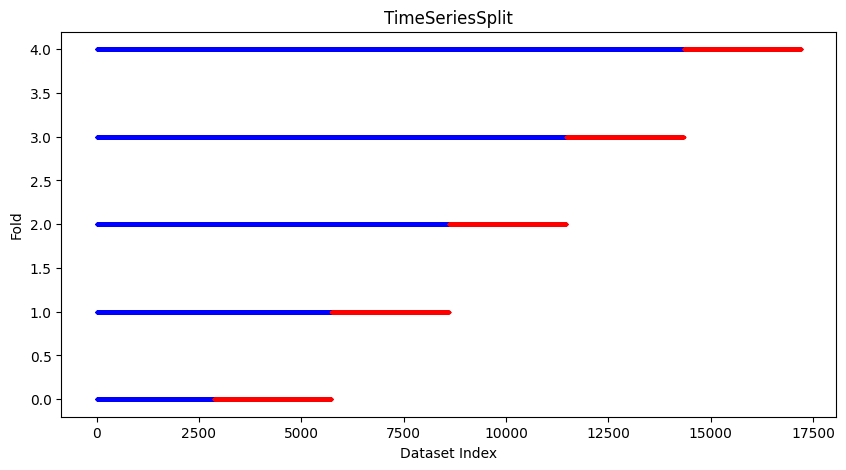

In [239]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):

    plt.scatter(train_idx,
                [fold]*len(train_idx),
                color="blue",
                s=2)

    plt.scatter(test_idx,
                [fold]*len(test_idx),
                color="red",
                s=2)

plt.xlabel("Dataset Index")
plt.ylabel("Fold")
plt.title("TimeSeriesSplit")
plt.show()

🔵 Blue = Training data
🔴 Red = Testing data<br>
Each fold trains on all previous observations and tests on future observations.

Unlike random train-test splitting, TimeSeriesSplit preserves the chronological order of observations. Each fold trains on past data and evaluates on future data, preventing data leakage and providing a realistic estimate of model performance in real-world forecasting scenarios.

## Baseline Model

Why do we need baselines?

Imagine your XGBoost model gives MAE = 42<br>
Is that good?<br>
You don't know unless you compare it with something simple.<br>
That's why we create baseline models first.

### Baseline 1 — Yesterday's Same Hour Demand (Naïve-24)
Idea:

Suppose you want to predict

Tuesday 3 PM

A simple assumption is:<br>
"Bike demand will be the same as yesterday at 3 PM."

Example

Time	Bike Count<br>
Monday 3 PM	250<br>
Tuesday 3 PM	?

Prediction

250<br>
This is called the Naïve-24 baseline.

In [240]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [241]:
prediction = df["lag_24"]
actual = df["cnt"]

In [242]:
y_true = df["cnt"]

y_pred = df["lag_24"]

In [243]:
#drop na
baseline1 = pd.DataFrame({
    "actual": y_true,
    "pred": y_pred
}).dropna()

In [244]:
#compute matrix

mae_naive = mean_absolute_error(
    baseline1["actual"],
    baseline1["pred"]
)

rmse_naive = np.sqrt(
    mean_squared_error(
        baseline1["actual"],
        baseline1["pred"]
    )
)

r2_naive = r2_score(
    baseline1["actual"],
    baseline1["pred"]
)

print("MAE :", mae_naive)
print("RMSE:", rmse_naive)
print("R²  :", r2_naive)

MAE : 65.36029283597699
RMSE: 110.52741336266935
R²  : 0.6300429720034595


The Naïve-24 baseline predicts the current hour's demand using the bike demand from the same hour on the previous day. It provides a strong benchmark because bike-sharing demand follows daily usage patterns.

#### Baseline 2 — Average Demand of Same Hour

Now we'll make a smarter baseline.
Instead of yesterday,
"What is the average demand at this hour?"

Example

Hour	Bike Count<br>
8 AM	300<br>
8 AM	320<br>
8 AM	340<br>
8 AM	310<br>

Average: 
317.5

Every future....8 AM  will predict 317.5

In [245]:
#calculate hourly avg
hr_mean = (
    df.groupby("hr")["cnt"].mean()
)

In [246]:
print(hr_mean)

hr
0      54.356546
1      33.617318
2      23.007062
3      11.740634
4       6.409289
5      20.050704
6      76.648536
7     213.530556
8     361.150000
9     220.618056
10    174.884722
11    209.602778
12    255.029126
13    255.375346
14    242.610803
15    252.952909
16    314.188105
17    464.467497
18    428.418863
19    313.676838
20    227.707351
21    173.578363
22    132.302358
23     88.507628
Name: cnt, dtype: float64


In [247]:
## Predict
# Map every hour to its average demand.

# df["hour_mean_pred"] = (
#     df["hr"]
#       .map(hour_mean)
# )

In [248]:
df_2 = pd.DataFrame({
    'hr' : df['hr'],
    'cnt' : df['cnt'],
    'mean' : df['hr'].map(hr_mean)
})

df_2.head()

,hr,cnt,mean
0,7,9,213.530556
1,8,15,361.150000
2,9,20,220.618056
3,10,61,174.884722
4,11,62,209.602778


In [249]:
y_true = df_2['cnt']
y_pred = df_2['mean']

mae_hour = mean_absolute_error(
    y_true,
    y_pred
)

rmse_hour = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

r2_hour = r2_score(
     y_true,
     y_pred
)

print("MAE :", mae_hour)
print("RMSE:", rmse_hour)
print("R² :", r2_hour)

MAE : 87.74303041356873
RMSE: 127.68479550610084
R² : 0.5062698602709195


This baseline predicts bike demand using the historical average demand for each hour of the day. It captures the daily demand pattern but ignores weather, seasonality, holidays, and recent demand trends.

In [250]:
#compare baseline

results = pd.DataFrame({
    "Model":[
        "Naive-24",
        "Hour Mean"
    ],
    "MAE":[
        mae_naive,
        mae_hour
    ],
    "RMSE":[
        rmse_naive,
        rmse_hour
    ],
    "R2":[
        r2_naive,
        r2_hour
    ]
})

results

,Model,MAE,RMSE,R2
0,Naive-24,65.360293,110.527413,0.630043
1,Hour Mean,87.743030,127.684796,0.506270


Naïve-24 wins because yesterday's demand is more informative than the long-term hourly average.

Two baseline forecasting models were evaluated. The Naïve-24 baseline, which predicts demand using the same hour from the previous day, outperformed the Hour Mean baseline, demonstrating that recent historical demand provides a stronger signal than the average hourly demand alone. These baselines serve as reference points for evaluating advanced machine learning models.

## Training Machine Learning Models

In [297]:
X = df.drop(columns=['cnt','datetime'])
y = df['cnt']

### 1.Linear Regression

In [298]:
# Linear Regression 

linear = LinearRegression()

linear_results = Evaluate_model(linear , X , y)
linear_results

{'MAE': np.float64(52.16515815253281),
 'RMSE': np.float64(74.96132217417876),
 'R2': np.float64(0.8215704394829982)}

### 2.Ridge Regression
Some features are highly correlated (for example, temp and atemp). Ridge reduces the impact of multicollinearity and can improve generalization.

In [253]:
# Ridge Regression

ridge = Ridge(alpha=1.0)

ridge_results = Evaluate_model(ridge , X , y)
ridge_results

{'MAE': np.float64(51.420985957221355),
 'RMSE': np.float64(74.14233714792249),
 'R2': np.float64(0.8264916943443849)}

### 3.Random Forest Regressor
Random Forest captures non-linear relationships and feature interactions without requiring extensive preprocessing.

In [254]:
# Random Forest

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_results = Evaluate_model(rf , X , y)
rf_results

{'MAE': np.float64(32.841758019525805),
 'RMSE': np.float64(53.754964201290726),
 'R2': np.float64(0.9061358306158216)}

### 4.XGBoost Regressor


In [255]:
# XG Boost 

xgb = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb_results = Evaluate_model(xgb,X,y)
xgb_results

{'MAE': np.float64(30.429611587524413),
 'RMSE': np.float64(47.44473305739481),
 'R2': np.float64(0.9245423316955567)}

### 5.LightGBM Regressor
LightGBM is optimized for speed and efficiency. It often trains faster than XGBoost while achieving comparable or better performance on large tabular datasets.

In [256]:
# LightGBM

lgbm = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42
)

lgbm_results = Evaluate_model(lgbm,X,y)
lgbm_results

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000307 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2339
[LightGBM] [Info] Number of data points in the train set: 2871, number of used features: 27
[LightGBM] [Info] Start training from score 97.387321
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000290 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2415
[LightGBM] [Info] Number of data points in the train set: 5739, number of used features: 27
[LightGBM] [Info] Start training from score 143.179648
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000874 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total B

{'MAE': np.float64(29.578018211316895),
 'RMSE': np.float64(46.32090065579878),
 'R2': np.float64(0.9291551701776074)}

### -----------------------------------
### Hyperparameter Tuning
### -----------------------------------

In [257]:
tscv = TimeSeriesSplit(n_splits=5)

### tune random forest

In [258]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 15, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0, "sqrt"]   # <-- include the default!
}

In [259]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_params,
    n_iter=50,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1

)

In [260]:
rf_search.fit(X,y)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 15, ...], 'max_features': [1.0, 'sqrt'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``

In [261]:
print(rf_search.best_params_)

{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': None}


In [262]:
# create
best_rf = rf_search.best_estimator_

In [263]:
best_rf_results = Evaluate_model(best_rf,X,y)

best_rf_results

{'MAE': np.float64(32.2980270470393),
 'RMSE': np.float64(53.15835391101355),
 'R2': np.float64(0.9086562170889895)}

### tune XGBoost

Step 1: Create Parameter Grid

In [264]:
from sklearn.model_selection import RandomizedSearchCV

xgb_params = {

    "n_estimators": [200, 300, 500],

    "learning_rate": [0.01, 0.03, 0.05, 0.1],

    "max_depth": [4, 5, 6, 8],

    "subsample": [0.8, 0.9, 1.0],

    "colsample_bytree": [0.8, 0.9, 1.0],

    "min_child_weight": [1, 3, 5]

}

Step 2: Create RandomizedSearchCV

In [265]:
xgb_search = RandomizedSearchCV(

    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42
    ),

    param_distributions=xgb_params,

    n_iter=30,

    cv=TimeSeriesSplit(n_splits=5),

    scoring="neg_mean_absolute_error",

    random_state=42,

    n_jobs=-1,

    refit=True

)

Step 3: Train

In [266]:
xgb_search.fit(X, y)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 0.9, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [4, 5, ...], 'min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` di

Step 4: Best Parameters

In [267]:
print(xgb_search.best_params_)

{'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 1.0}


Step 5: Best Model

In [268]:
best_xgb = xgb_search.best_estimator_

In [269]:
best_xgb_results = Evaluate_model(best_xgb, X, y)

best_xgb_results

{'MAE': np.float64(29.311259078979493),
 'RMSE': np.float64(46.05862309986804),
 'R2': np.float64(0.9293869972229004)}

### Tuing lightgbm with optuna
Create the Objective Function

In [270]:
def objective(trial):

    params = {

        "n_estimators": trial.suggest_int(
            "n_estimators",
            100,
            500
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.1,
            log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            4,
            10
        ),

        "num_leaves": trial.suggest_int(
            "num_leaves",
            20,
            100
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.7,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.7,
            1.0
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            10,
            50
        ),

        "random_state":42,

        "n_jobs":-1

    }

    model = LGBMRegressor(**params)

    mae_scores = []

    for train_idx, test_idx in tscv.split(X):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        mae = mean_absolute_error(
            y_test,
            predictions
        )

        mae_scores.append(mae)

    return np.mean(mae_scores)

In [271]:
#start optimization
study = optuna.create_study(
    direction="minimize"
)

study.optimize(
    objective,
    n_trials=30
)

[I 2026-07-30 10:47:51,953] A new study created in memory with name: no-name-f25130fd-a55a-4810-bbd2-7402a99b5c41


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000243 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2339
[LightGBM] [Info] Number of data points in the train set: 2871, number of used features: 27
[LightGBM] [Info] Start training from score 97.387321
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

[I 2026-07-30 10:47:58,071] Trial 0 finished with value: 30.057938247831782 and parameters: {'n_estimators': 406, 'learning_rate': 0.03274768516552208, 'max_depth': 6, 'num_leaves': 84, 'subsample': 0.9504832329081013, 'colsample_bytree': 0.9788480309312824, 'min_child_samples': 40}. Best is trial 0 with value: 30.057938247831782.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2026-07-30 10:48:06,021] Trial 1 finished with value: 29.744308531138028 and parameters: {'n_estimators': 489, 'learning_rate': 0.017996309229818663, 'max_depth': 10, 'num_leaves': 26, 'subsample': 0.9688274950088887, 'colsample_bytree': 0.8501806144774853, 'min_child_samples': 32}. Best is trial 1 with value: 29.744308531138028.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000311 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2339
[LightGBM] [Info] Number of data points in the train set: 2871, number of used features: 27
[LightGBM] [Info] Start training from score 97.387321
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

... (52 outputs left out)

[I 2026-07-30 10:51:36,506] Trial 28 finished with value: 29.507222918384194 and parameters: {'n_estimators': 394, 'learning_rate': 0.028880694050894176, 'max_depth': 9, 'num_leaves': 51, 'subsample': 0.8413786223969767, 'colsample_bytree': 0.9625427389743504, 'min_child_samples': 21}. Best is trial 24 with value: 29.376608864976454.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000338 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [I

[I 2026-07-30 10:51:41,158] Trial 29 finished with value: 29.834623986288126 and parameters: {'n_estimators': 427, 'learning_rate': 0.03382689473830984, 'max_depth': 5, 'num_leaves': 46, 'subsample': 0.7488537381673414, 'colsample_bytree': 0.8469321061227779, 'min_child_samples': 32}. Best is trial 24 with value: 29.376608864976454.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [272]:
#Best Trial
print("Best MAE")

print(study.best_value)

print()

print("Best Parameters")

print(study.best_params)

Best MAE
29.376608864976454

Best Parameters
{'n_estimators': 428, 'learning_rate': 0.020817332201831566, 'max_depth': 8, 'num_leaves': 40, 'subsample': 0.7795390131112314, 'colsample_bytree': 0.8102806874704006, 'min_child_samples': 11}


In [273]:
#Train Final LightGBM
best_lgbm = LGBMRegressor(

    **study.best_params,

    random_state=42,

    n_jobs=-1

)

In [274]:
#evaluate
best_lgbm_results = Evaluate_model(
    best_lgbm,
    X,
    y
)

best_lgbm_results

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000212 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2339
[LightGBM] [Info] Number of data points in the train set: 2871, number of used features: 27
[LightGBM] [Info] Start training from score 97.387321
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

{'MAE': np.float64(29.376608864976454),
 'RMSE': np.float64(46.60504923264317),
 'R2': np.float64(0.9280850227132047)}

In [275]:
best_lgbm.fit(X, y)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000463 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2450
[LightGBM] [Info] Number of data points in the train set: 17211, number of used features: 28
[LightGBM] [Info] Start training from score 190.761374
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


,num_leaves,40
,max_depth,8
,learning_rate,0.020817332201831566
,n_estimators,428
,min_child_samples,11
,subsample,0.7795390131112314
,colsample_bytree,0.8102806874704006
,random_state,42
,n_jobs,-1
,boosting_type,'gbdt'
,subsample_for_bin,200000


### Compare All Models

In [276]:
comparison = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Random Forest (Tuned)",
        "XGBoost",
        "XGBoost (Tuned)",
        "LightGBM",
        "LightGBM (Tuned)"
    ],

    "MAE": [
        linear_results["MAE"],
        ridge_results["MAE"],
        rf_results["MAE"],
        best_rf_results["MAE"],
        xgb_results["MAE"],
        best_xgb_results["MAE"],
        lgbm_results["MAE"],
        best_lgbm_results["MAE"]
    ],

    "RMSE": [
        linear_results["RMSE"],
        ridge_results["RMSE"],
        rf_results["RMSE"],
        best_rf_results["RMSE"],
        xgb_results["RMSE"],
        best_xgb_results["RMSE"],
        lgbm_results["RMSE"],
        best_lgbm_results["RMSE"]
    ],

    "R²": [
        linear_results["R2"],
        ridge_results["R2"],
        rf_results["R2"],
        best_rf_results["R2"],
        xgb_results["R2"],
        best_xgb_results["R2"],
        lgbm_results["R2"],
        best_lgbm_results["R2"]
    ]

})

comparison = comparison.sort_values(by="MAE").reset_index(drop=True)

comparison

,Model,MAE,RMSE,R²
0,XGBoost (Tuned),29.311259,46.058623,0.929387
1,LightGBM (Tuned),29.376609,46.605049,0.928085
2,LightGBM,29.578018,46.320901,0.929155
3,XGBoost,30.429612,47.444733,0.924542
4,Random Forest (Tuned),32.298027,53.158354,0.908656
5,Random Forest,32.841758,53.754964,0.906136
6,Ridge Regression,51.420986,74.142337,0.826492
7,Linear Regression,52.165158,74.961322,0.821570


In [277]:
comparison.style.format({
    "MAE": "{:.2f}",
    "RMSE": "{:.2f}",
    "R²": "{:.4f}"
}).highlight_min(subset=["MAE","RMSE"], color="lightgreen") \
  .highlight_max(subset=["R²"], color="lightgreen")

,Model,MAE,RMSE,R²
0,XGBoost (Tuned),29.31,46.06,0.9294
1,LightGBM (Tuned),29.38,46.61,0.9281
2,LightGBM,29.58,46.32,0.9292
3,XGBoost,30.43,47.44,0.9245
4,Random Forest (Tuned),32.30,53.16,0.9087
5,Random Forest,32.84,53.75,0.9061
6,Ridge Regression,51.42,74.14,0.8265
7,Linear Regression,52.17,74.96,0.8216


Hence the best model is Lightgbm(tuned)

In [299]:
best_model =  best_xgb

best_model.fit(X,y)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [300]:
joblib.dump(
    best_model,
    '../models/ridewise_model.joblib'
)

['../models/ridewise_model.joblib']

Five machine learning models were evaluated using 5-fold TimeSeriesSplit cross-validation. Gradient boosting models outperformed linear and bagging-based models, demonstrating their ability to capture complex nonlinear relationships in bike demand. Hyperparameter tuning further improved XGBoost, which achieved the lowest MAE , lowest RMSE , and highest R² . Therefore, the tuned XGBoost model was selected as the final forecasting model for deployment.

## Generate SHAP explanations

In [301]:
#import libraries
import shap

#### 1.Create SHAP Explainer

Since XGBoost is tree-based:

In [302]:
explainer = shap.TreeExplainer(best_model)

#### 2: Compute SHAP Values
If you're using SHAP ≥ 0.40 (recommended)

In [303]:
shap_values = explainer(X)
print(type(shap_values))

<class 'shap._explanation.Explanation'>


#### 3.Global Feature Importance (Bar Plot)

This tells us which features matter the most overall.<br>
The features at the top contribute the most to the model.

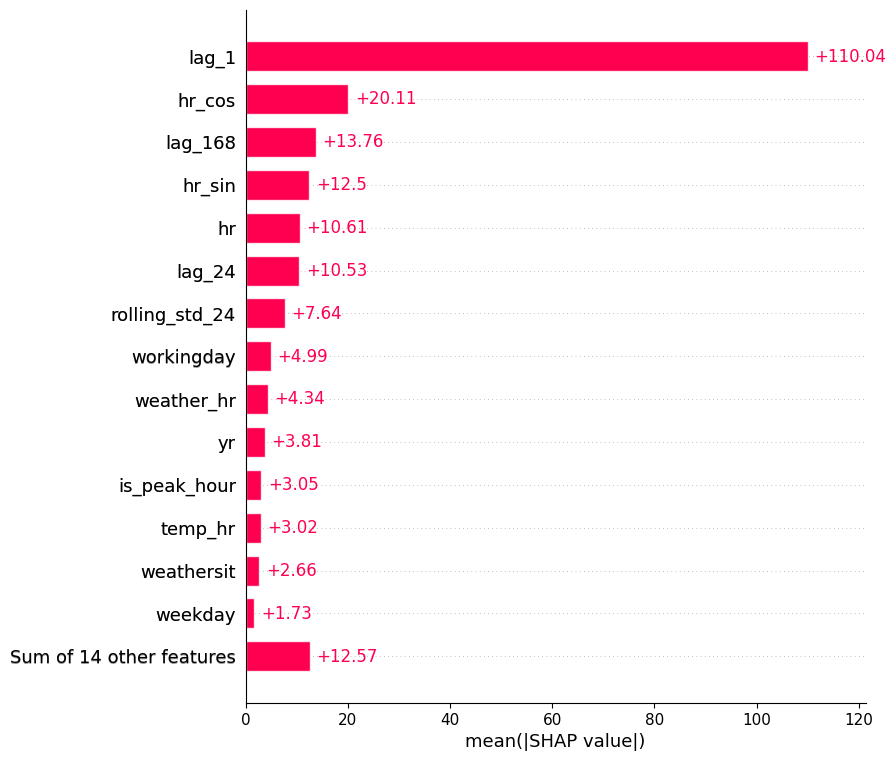

In [304]:
shap.plots.bar(shap_values, max_display=15)

The SHAP feature importance plot ranks features based on their average contribution to model predictions. Features with higher SHAP values have a greater influence on predicted bike demand.

#### 4.SHAP Summary Plot

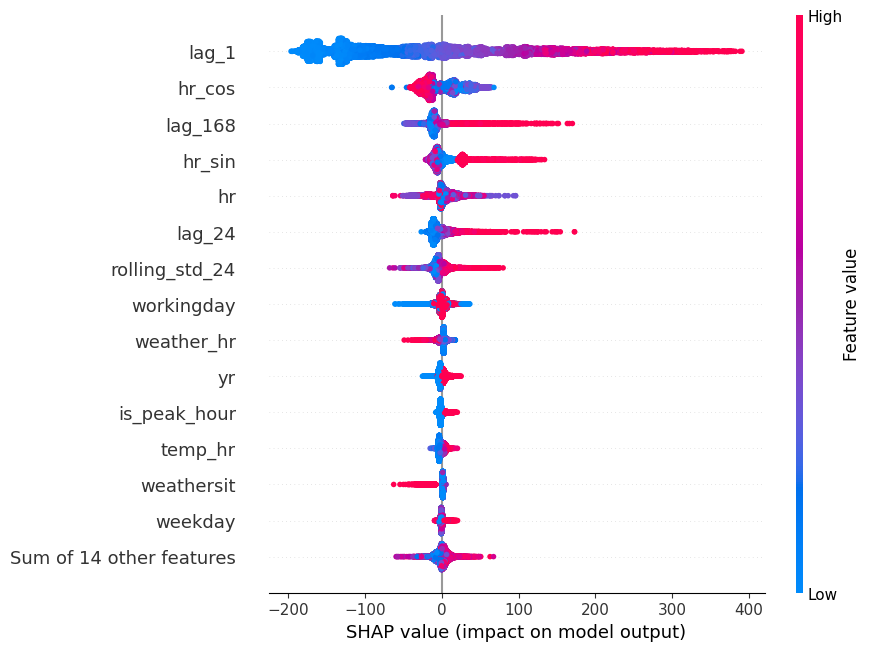

In [305]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

#### 5.Waterfall Plot

This explains one individual prediction.

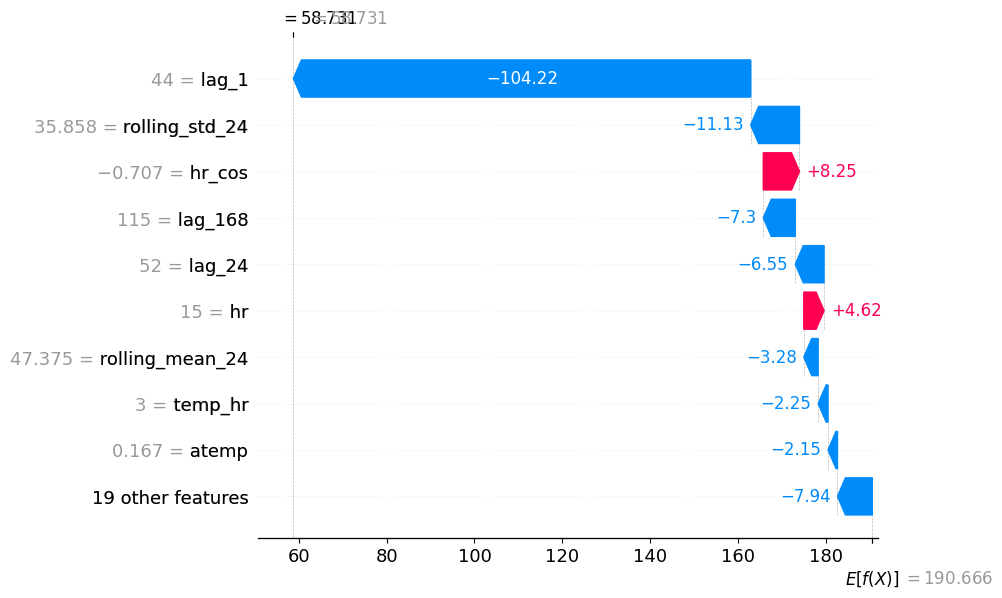

In [306]:
sample_index = 100

#generate explanation
sample = X.iloc[[sample_index]]
sample_shap = explainer(sample)

#plot
shap.plots.waterfall(sample_shap[0])

#### 6.Feature Importance Table

In [307]:
feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Mean |SHAP|": np.abs(
        shap_values.values
    ).mean(axis=0)

})

feature_importance = feature_importance.sort_values(

    by="Mean |SHAP|",

    ascending=False

)

feature_importance.head(15)

,Feature,Mean |SHAP|
18,lag_1,110.035629
13,hr_cos,20.109743
20,lag_168,13.759732
12,hr_sin,12.496764
3,hr,10.614489
19,lag_24,10.525074
23,rolling_std_24,7.644065
6,workingday,4.994545
26,weather_hr,4.336792
1,yr,3.808872


#### 7.Plot Top 10 Features

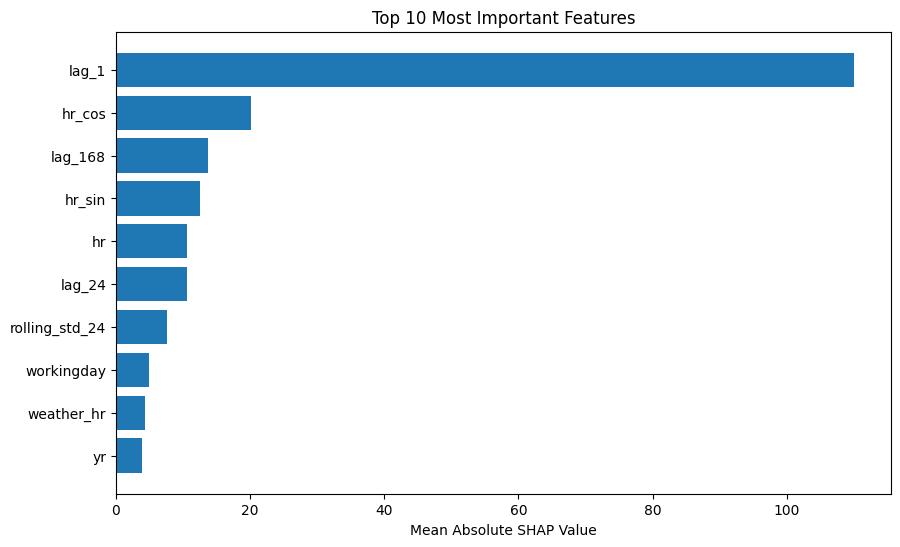

In [308]:
top10 = feature_importance.head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top10["Feature"],
    top10["Mean |SHAP|"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mean Absolute SHAP Value")

plt.title("Top 10 Most Important Features")

plt.show()

SHAP analysis identified lag_24 as the most influential feature for predicting hourly bike demand. This indicates that demand at the same hour on the previous day is the strongest predictor of current demand. Other important features include rolling_mean_24, temperature, and cyclical hour encodings, highlighting the importance of historical demand patterns, weather conditions, and daily commuting cycles.

### Saving Feature Names

In [309]:
feature_names = X.columns.tolist()

joblib.dump(feature_names, "../models/features.joblib")

['../models/features.joblib']

## Building Model 2(For future forecasting)

In [310]:
df_2 = pd.read_csv('../data/processed/hour_features.csv')
df_2.head()

,datetime,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,lag_1,lag_24,lag_168,rolling_mean_24,rolling_median_24,rolling_std_24,is_peak_hour,temp_hr,weather_hr,temp_hum
0,2011-01-08 07:00:00,1,0,1,7,0,6,0,2,0.16,...,2.0,84.0,16.0,60.083333,50.5,56.721989,1,1.12,14,0.1184
1,2011-01-08 08:00:00,1,0,1,8,0,6,0,3,0.16,...,9.0,210.0,40.0,51.958333,44.5,47.536237,1,1.28,24,0.1488
2,2011-01-08 09:00:00,1,0,1,9,0,6,0,3,0.16,...,15.0,134.0,32.0,47.208333,37.5,44.585998,1,1.44,27,0.1488
3,2011-01-08 10:00:00,1,0,1,10,0,6,0,2,0.18,...,20.0,63.0,13.0,47.125000,37.5,44.557059,0,1.80,20,0.1440
4,2011-01-08 11:00:00,1,0,1,11,0,6,0,2,0.20,...,61.0,67.0,1.0,46.916667,37.5,44.471698,0,2.20,22,0.1380


In [311]:
df_2.drop(columns=['lag_1','lag_24','lag_168','rolling_mean_24','rolling_median_24','rolling_std_24'] , inplace=True)
df_2.to_csv('../data/processed/hour_features_2.csv')
df_2.head()

,datetime,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,...,hr_sin,hr_cos,weekday_sin,weekday_cos,month_sin,month_cos,is_peak_hour,temp_hr,weather_hr,temp_hum
0,2011-01-08 07:00:00,1,0,1,7,0,6,0,2,0.16,...,0.965926,-0.258819,-0.781831,0.62349,0.5,0.866025,1,1.12,14,0.1184
1,2011-01-08 08:00:00,1,0,1,8,0,6,0,3,0.16,...,0.866025,-0.500000,-0.781831,0.62349,0.5,0.866025,1,1.28,24,0.1488
2,2011-01-08 09:00:00,1,0,1,9,0,6,0,3,0.16,...,0.707107,-0.707107,-0.781831,0.62349,0.5,0.866025,1,1.44,27,0.1488
3,2011-01-08 10:00:00,1,0,1,10,0,6,0,2,0.18,...,0.500000,-0.866025,-0.781831,0.62349,0.5,0.866025,0,1.80,20,0.1440
4,2011-01-08 11:00:00,1,0,1,11,0,6,0,2,0.20,...,0.258819,-0.965926,-0.781831,0.62349,0.5,0.866025,0,2.20,22,0.1380


In [312]:
X = df_2.drop(columns=['cnt'])
X.set_index('datetime', inplace=True)

y = df_2['cnt']

X.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,...,hr_sin,hr_cos,weekday_sin,weekday_cos,month_sin,month_cos,is_peak_hour,temp_hr,weather_hr,temp_hum
datetime,,,,,,,,,,,,,,,,,,,,,
2011-01-08 07:00:00,1,0,1,7,0,6,0,2,0.16,0.1818,...,0.965926,-0.258819,-0.781831,0.62349,0.5,0.866025,1,1.12,14,0.1184
2011-01-08 08:00:00,1,0,1,8,0,6,0,3,0.16,0.1818,...,0.866025,-0.500000,-0.781831,0.62349,0.5,0.866025,1,1.28,24,0.1488
2011-01-08 09:00:00,1,0,1,9,0,6,0,3,0.16,0.1818,...,0.707107,-0.707107,-0.781831,0.62349,0.5,0.866025,1,1.44,27,0.1488
2011-01-08 10:00:00,1,0,1,10,0,6,0,2,0.18,0.1970,...,0.500000,-0.866025,-0.781831,0.62349,0.5,0.866025,0,1.80,20,0.1440
2011-01-08 11:00:00,1,0,1,11,0,6,0,2,0.20,0.1818,...,0.258819,-0.965926,-0.781831,0.62349,0.5,0.866025,0,2.20,22,0.1380


In [313]:
xgb2 = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb2_results = Evaluate_model(xgb2,X,y)
xgb2_results

{'MAE': np.float64(47.71497268676758),
 'RMSE': np.float64(70.84205170355983),
 'R2': np.float64(0.824343490600586)}

#### Hyperparameter Tuning

In [314]:
xgb_params = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [4, 5, 6, 8],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42
    ),
    param_distributions=xgb_params,
    n_iter=30,
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    refit=True
)

xgb_search.fit(X, y)

print(xgb_search.best_params_)


best_xgb = xgb_search.best_estimator_

best_xgb_results = Evaluate_model(best_xgb, X, y)
best_xgb_results

{'subsample': 0.9, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


{'MAE': np.float64(45.988179779052736),
 'RMSE': np.float64(68.30932272068729),
 'R2': np.float64(0.8383926153182983)}

In [315]:
best_model2 = best_xgb

best_model2.fit(X,y)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [316]:
joblib.dump(
    best_model2,
    '../models/future_ridewise_model.joblib'
)

['../models/future_ridewise_model.joblib']

In [317]:
feature_names = X.columns.tolist()

joblib.dump(feature_names, "../models/future_features.joblib")

['../models/future_features.joblib']